# House Price Prediction — Phase 1: Data Understanding and Preprocessing

**Dataset:** Kaggle *House Prices: Advanced Regression Techniques* (Ames, Iowa housing data)

**What this notebook does (Phase 1 only):** loads and validates the data, explores it, treats missing values, checks data quality and outliers, engineers features, analyses the target, prepares leakage-safe train/validation/test matrices, encodes and scales them, runs final quality checks, and saves everything to disk.

**What this notebook does NOT do:** train any model, tune anything, compute regression metrics, or make predictions. That is Phase 2.

## How to run
1. Keep `train.csv` and `test.csv` in the **same folder** as this notebook.
2. Run the cells from top to bottom (**Kernel → Restart & Run All**).
3. A folder called `outputs/` is created automatically with all saved files.

## Roadmap (matches the 10 steps of the project brief)
| Step | Topic |
|---|---|
| 1 | Dataset loading and validation |
| 2 | Exploratory Data Analysis (EDA) |
| 3 | Missing-value analysis and treatment |
| 4 | Data quality and outlier analysis |
| 5 | Feature engineering |
| 6 | Target variable analysis |
| 7 | Leakage-safe data preparation |
| 8 | Encoding and scaling |
| 9 | Final quality checks |
| 10 | Saving the outputs |

## 0. Setup

### 0.1 Installing libraries
If any import in the next cells fails, remove the `#` in front of the line below, run the cell once, then **restart the kernel**.

In [1]:
# Remove the "#" below and run once ONLY if an import fails.
# !pip install pandas numpy matplotlib seaborn scikit-learn joblib

### 0.2 Imports, settings, and output folders

- `Path` (from `pathlib`) builds file paths safely on Windows, Mac, and Linux.
- `RANDOM_STATE = 42` makes the train/validation split identical every time you run the notebook (**reproducibility**).
- We create organised output folders so saved files are easy to find:
  - `outputs/reports/` → missing-value report, outlier report, transformation log
  - `outputs/plots/` → all saved figures
  - `outputs/analysis/` → cleaned data that is still human-readable (**for analysis**)
  - `outputs/model_ready/` → fully encoded and scaled matrices (**for modeling**)

In [48]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

# The CSV files are in the same folder as this notebook
TRAIN_PATH = Path("train.csv")
TEST_PATH = Path("test.csv")

# Output folders (created automatically)
OUTPUT_DIR = Path("outputs")
REPORT_DIR = OUTPUT_DIR / "reports"
PLOT_DIR = OUTPUT_DIR / "plots"
ANALYSIS_DIR = OUTPUT_DIR / "analysis"
MODEL_DIR = OUTPUT_DIR / "model_ready"

for folder in [REPORT_DIR, PLOT_DIR, ANALYSIS_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Show all columns when printing tables (this dataset has 81 columns)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme()

# A running record of every transformation we make and why (saved at the end)
transformation_log = []

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 2.3.3
numpy: 2.3.5
scikit-learn: 1.7.2


> **Version note:** this notebook uses `OneHotEncoder(sparse_output=False)`, which needs **scikit-learn 1.2 or newer**. If you see a `TypeError` mentioning `sparse_output`, run `!pip install --upgrade scikit-learn` and restart the kernel.

---
# Step 1: Dataset loading and validation

**Why this step exists:** every later decision depends on knowing exactly what we have. Catching a wrong file path, a train/test column mismatch, or an impossible value *now* is far cheaper than discovering it after modeling.

### 1.1 Verify the file paths
We check that both files exist **before** loading, so a mistake gives a clear message instead of a confusing pandas error.

In [49]:
print("Notebook is running from:", Path.cwd())
print("train.csv found:", TRAIN_PATH.exists())
print("test.csv found: ", TEST_PATH.exists())

if not TRAIN_PATH.exists() or not TEST_PATH.exists():
    print("\nFiles in this folder:", [p.name for p in Path.cwd().iterdir()])
    raise FileNotFoundError("Put train.csv and test.csv in the same folder as this notebook, then re-run.")

Notebook is running from: /Users/suhanimalhotra/house_price_prediction
train.csv found: True
test.csv found:  True


### 1.2 Load the data and keep untouched copies
`train_raw` and `test_raw` are our **originals**. We never modify them. All cleaning happens on `train` and `test`, which are independent copies.

> **Why `.copy()`?** Without it, `train = train_raw` would only create a second *name* for the same table, and changing one would silently change the other.
>
> The CSV files on disk are also safe because this notebook only ever *reads* them.

In [50]:
train_raw = pd.read_csv(TRAIN_PATH)
test_raw = pd.read_csv(TEST_PATH)

train = train_raw.copy()
test = test_raw.copy()

print("Train shape:", train.shape)
print("Test shape: ", test.shape)

Train shape: (1460, 81)
Test shape:  (1459, 80)


**What to expect:** the Kaggle competition page lists about 1460 rows × 81 columns for train and about 1459 rows × 80 columns for test. Test has one fewer column because it does not contain `SalePrice` (that is what Kaggle asks you to predict).

### 1.3 Column names, first rows, and data types

In [51]:
print("First 3 rows of train:")
display(train.head(3))

print("\nFirst 3 rows of test:")
display(test.head(3))

print("\nTrain column names:")
print(list(train.columns))

First 3 rows of train:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500



First 3 rows of test:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal



Train column names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch',

In [52]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [53]:
print("Count of columns by data type:")
print(train.dtypes.value_counts())

numeric_cols = train.select_dtypes(include=np.number).columns.tolist()
text_cols = train.select_dtypes(exclude=np.number).columns.tolist()
print("\nNumeric columns:", len(numeric_cols))
print("Text (categorical) columns:", len(text_cols))

Count of columns by data type:
object     43
int64      35
float64     3
Name: count, dtype: int64

Numeric columns: 38
Text (categorical) columns: 43


**Two things to notice (we handle both properly later):**
1. `MSSubClass` is stored as a number but it is really a **category code** (20, 30, 60… are building types). Averaging them is meaningless. We convert it to a category in Step 7.
2. `.info()` shows non-null counts below the row total for some columns. Those are missing values (Step 3).

### 1.4 Target variable and ID column
- **Target (`SalePrice`)**: what we want to predict. It exists in train only.
- **ID (`Id`)**: just a row label. If a model used it as a feature it could learn meaningless patterns from row order. We separate it later but keep the test IDs, because Kaggle needs them to match predictions to houses.

In [54]:
target_col = "SalePrice"
id_col = "Id"

print("SalePrice in train:", target_col in train.columns)
print("SalePrice in test: ", target_col in test.columns, "(should be False)")
print("Id in train:", id_col in train.columns, "| Id in test:", id_col in test.columns)

print("\nSalePrice data type:", train[target_col].dtype)
print("Missing SalePrice values:", train[target_col].isna().sum())
print("Id range in train:", train[id_col].min(), "to", train[id_col].max())
print("Id range in test: ", test[id_col].min(), "to", test[id_col].max())

SalePrice in train: True
SalePrice in test:  False (should be False)
Id in train: True | Id in test: True

SalePrice data type: int64
Missing SalePrice values: 0
Id range in train: 1 to 1460
Id range in test:  1461 to 2919


### 1.5 Duplicate rows and duplicate IDs
Duplicate rows can double-count a house and make validation scores look better than they really are. Duplicate IDs would signal a data-collection problem. IDs shared between train and test would mean the two sets overlap.

In [55]:
print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate rows in test: ", test.duplicated().sum())

print("\nDuplicate Ids in train:", train[id_col].duplicated().sum())
print("Duplicate Ids in test: ", test[id_col].duplicated().sum())

shared_ids = set(train[id_col]) & set(test[id_col])
print("\nIds appearing in BOTH train and test:", len(shared_ids))

Duplicate rows in train: 0
Duplicate rows in test:  0

Duplicate Ids in train: 0
Duplicate Ids in test:  0

Ids appearing in BOTH train and test: 0


### 1.6 Train/test schema differences
Train and test must have the same feature columns. The only difference allowed is that train has `SalePrice`.

In [56]:
train_features = set(train.columns) - {target_col}
test_features = set(test.columns)

print("Columns only in train (besides SalePrice):", sorted(train_features - test_features))
print("Columns only in test:", sorted(test_features - train_features))

# Same column, different data type in train vs test?
dtype_differences = []
for col in test.columns:
    if train[col].dtype != test[col].dtype:
        dtype_differences.append((col, str(train[col].dtype), str(test[col].dtype)))

print("\nColumns whose data type differs between train and test:")
if len(dtype_differences) == 0:
    print("  None")
else:
    for item in dtype_differences:
        print("  ", item)

assert train_features == test_features, "Train/test feature columns differ. Investigate before continuing."
print("\nSchema check passed.")

Columns only in train (besides SalePrice): []
Columns only in test: []

Columns whose data type differs between train and test:
   ('BsmtFinSF1', 'int64', 'float64')
   ('BsmtFinSF2', 'int64', 'float64')
   ('BsmtUnfSF', 'int64', 'float64')
   ('TotalBsmtSF', 'int64', 'float64')
   ('BsmtFullBath', 'int64', 'float64')
   ('BsmtHalfBath', 'int64', 'float64')
   ('GarageCars', 'int64', 'float64')
   ('GarageArea', 'int64', 'float64')

Schema check passed.


*A data type difference is usually harmless.* For example, an integer column that contains missing values becomes `float` (because `NaN` is a float), so it can differ between files.

### 1.7 Check for unexpected values
We look for four kinds of problems and only **report** them here. Decisions come in Step 4.

1. Blank or whitespace-only text values
2. Negative numbers where negatives are impossible (areas, counts, prices, years)
3. Year columns outside a sensible range
4. Logical contradictions (a house remodeled before it was built, sold before it was built, or with a garage built after the sale)

In [57]:
# 1) Blank / whitespace-only text values
blank_found = False
for col in text_cols:
    blank_count = (train[col].str.strip() == "").sum()
    if blank_count > 0:
        print("Blank text values in", col, ":", blank_count)
        blank_found = True
if not blank_found:
    print("No blank text values found in train.")

# 2) Negative values in numeric columns
negative_counts = (train[numeric_cols] < 0).sum()
print("\nNumeric columns containing negative values:")
print(negative_counts[negative_counts > 0] if (negative_counts > 0).any() else "  None")

No blank text values found in train.

Numeric columns containing negative values:
  None


In [58]:
# 3) Year ranges in train and test
print("Year column ranges:")
for col in ["YearBuilt", "YearRemodAdd", "GarageYrBlt", "YrSold"]:
    print(col, "| train:", train[col].min(), "to", train[col].max(),
          "| test:", test[col].min(), "to", test[col].max())

# 4) Logical contradictions
print("\nLogical checks (train, test):")
print("Remodeled before built :", (train["YearRemodAdd"] < train["YearBuilt"]).sum(),
      (test["YearRemodAdd"] < test["YearBuilt"]).sum())
print("Sold before built      :", (train["YrSold"] < train["YearBuilt"]).sum(),
      (test["YrSold"] < test["YearBuilt"]).sum())
print("Garage built after sale:", (train["GarageYrBlt"] > train["YrSold"]).sum(),
      (test["GarageYrBlt"] > test["YrSold"]).sum())

# Show any garage year that is impossible (later than the latest sale year in the data)
latest_sale_year = max(train["YrSold"].max(), test["YrSold"].max())
print("\nHouses with a garage year later than", latest_sale_year, "(impossible):")
display(train[train["GarageYrBlt"] > latest_sale_year][["Id", "GarageYrBlt", "YearBuilt", "YrSold"]])
display(test[test["GarageYrBlt"] > latest_sale_year][["Id", "GarageYrBlt", "YearBuilt", "YrSold"]])

Year column ranges:
YearBuilt | train: 1872 to 2010 | test: 1879 to 2010
YearRemodAdd | train: 1950 to 2010 | test: 1950 to 2010
GarageYrBlt | train: 1900.0 to 2010.0 | test: 1895.0 to 2207.0
YrSold | train: 2006 to 2010 | test: 2006 to 2010

Logical checks (train, test):
Remodeled before built : 0 1
Sold before built      : 0 1
Garage built after sale: 0 2

Houses with a garage year later than 2010 (impossible):


,Id,GarageYrBlt,YearBuilt,YrSold


,Id,GarageYrBlt,YearBuilt,YrSold
1132,2593,2207.0,2006,2007


**Reading these results:** the Ames data is known to contain a small number of impossible or odd values, such as a garage "built" in a future year like 2207. If you see rows in the last two tables, that is a real **data error**, and we record the decision in Step 4.

Next, a quick look at which labels each text column contains. We are looking for typos or inconsistent spellings of the same category.

In [59]:
for col in text_cols:
    values = sorted(train[col].dropna().unique())
    print(col, "->", values)

MSZoning -> ['C (all)', 'FV', 'RH', 'RL', 'RM']
Street -> ['Grvl', 'Pave']
Alley -> ['Grvl', 'Pave']
LotShape -> ['IR1', 'IR2', 'IR3', 'Reg']
LandContour -> ['Bnk', 'HLS', 'Low', 'Lvl']
Utilities -> ['AllPub', 'NoSeWa']
LotConfig -> ['Corner', 'CulDSac', 'FR2', 'FR3', 'Inside']
LandSlope -> ['Gtl', 'Mod', 'Sev']
Neighborhood -> ['Blmngtn', 'Blueste', 'BrDale', 'BrkSide', 'ClearCr', 'CollgCr', 'Crawfor', 'Edwards', 'Gilbert', 'IDOTRR', 'MeadowV', 'Mitchel', 'NAmes', 'NPkVill', 'NWAmes', 'NoRidge', 'NridgHt', 'OldTown', 'SWISU', 'Sawyer', 'SawyerW', 'Somerst', 'StoneBr', 'Timber', 'Veenker']
Condition1 -> ['Artery', 'Feedr', 'Norm', 'PosA', 'PosN', 'RRAe', 'RRAn', 'RRNe', 'RRNn']
Condition2 -> ['Artery', 'Feedr', 'Norm', 'PosA', 'PosN', 'RRAe', 'RRAn', 'RRNn']
BldgType -> ['1Fam', '2fmCon', 'Duplex', 'Twnhs', 'TwnhsE']
HouseStyle -> ['1.5Fin', '1.5Unf', '1Story', '2.5Fin', '2.5Unf', '2Story', 'SFoyer', 'SLvl']
RoofStyle -> ['Flat', 'Gable', 'Gambrel', 'Hip', 'Mansard', 'Shed']
RoofMatl -

*What to look for:* labels that look like two spellings of one thing. Scan `Exterior1st` and `Exterior2nd` in particular. If a spelling mismatch exists it simply produces two separate one-hot columns, which is harmless for a baseline, but worth knowing and mentioning.

### Interview explanation for Step 1
> "Before any analysis I validated the raw data: file paths, shapes, the target and ID columns, duplicate rows and IDs, train/test schema differences, and impossible values like negative areas or contradictory years. I kept untouched copies of the originals so every later change is traceable."

**Limitation:** these checks only catch problems we thought to test for. EDA (Step 2) will reveal more.

---
# Step 2: Exploratory Data Analysis (EDA)

**Goal:** understand shapes, relationships, and problems in the data so that every preprocessing decision is justified by evidence rather than guesswork.

### 2.1 Numerical summary statistics
`describe()` shows count, mean, standard deviation, min, quartiles, and max for each numeric column.

In [60]:
display(train.describe().T)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


**What to look for:**
- `count` smaller than the number of rows → missing values (e.g. `LotFrontage`, `MasVnrArea`, `GarageYrBlt`).
- `mean` far above the `50%` (median) → right-skewed column with a long tail (e.g. `LotArea`, `SalePrice`).
- `max` far above the `75%` quartile → possible outliers (Step 4).
- `min = 0` in area columns usually means "this feature does not exist" (no pool, no basement, no porch), not a measurement of zero.

### 2.2 Categorical summary
For text columns: how many different values (`unique`), the most common value (`top`), and how often it appears (`freq`).

In [61]:
display(train[text_cols].describe().T)

,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


**What to look for:** columns where `top` accounts for almost every row (e.g. `Utilities`, `Street`, `Condition2`, `RoofMatl`) carry almost no information, because nearly every house has the same value. We keep them in this baseline, but this is a note for the modeling phase.

### 2.3 Distributions of important numeric features
Histograms show the *shape* of a feature. The smooth line (KDE) is just a smoothed version of the histogram. We save each plot into `outputs/plots/`.

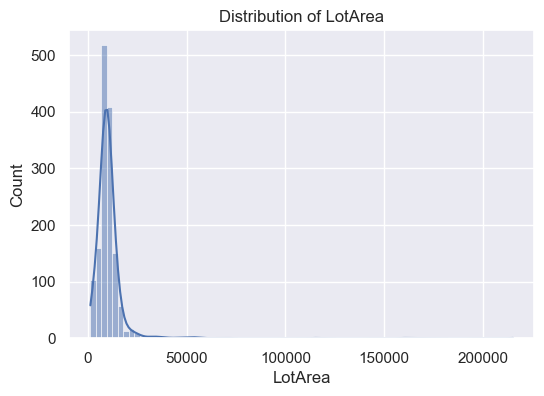

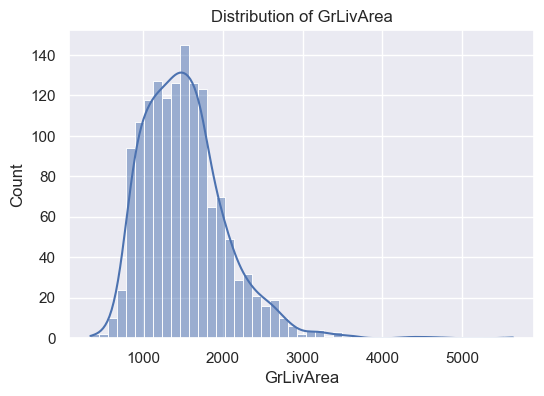

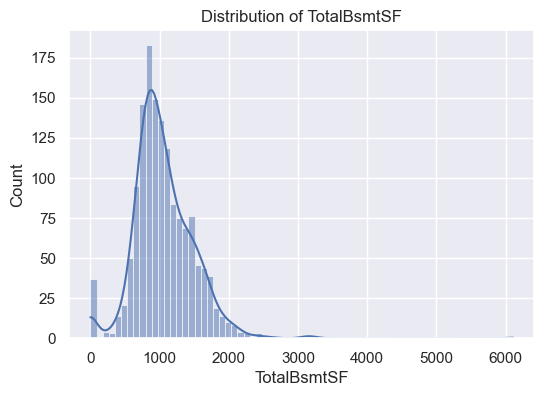

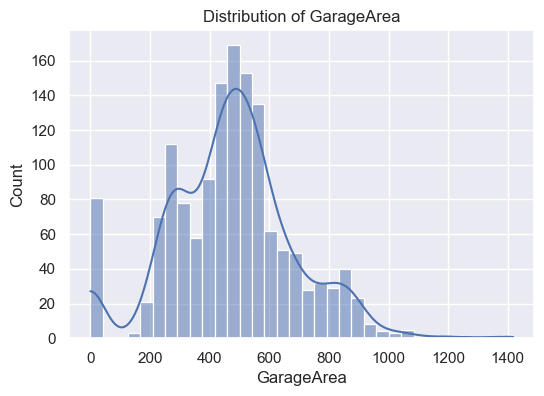

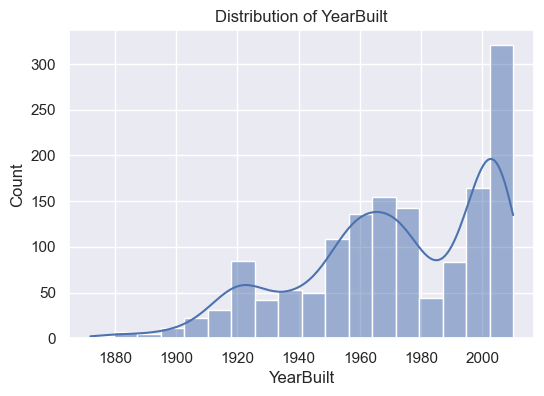

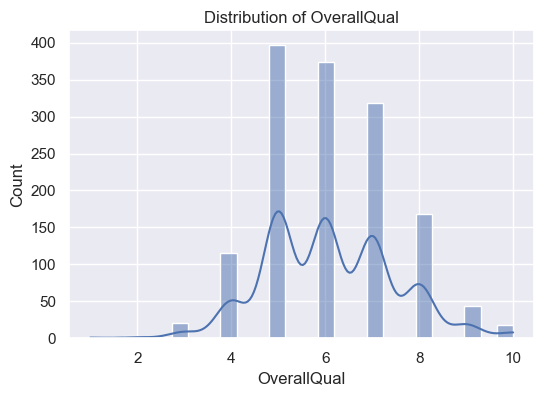

In [62]:
eda_numeric_features = ["LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt", "OverallQual"]

for col in eda_numeric_features:
    plt.figure(figsize=(6, 4))
    sns.histplot(train[col], kde=True)
    plt.title("Distribution of " + col)
    plt.savefig(PLOT_DIR / ("hist_" + col + ".png"), bbox_inches="tight")
    plt.show()

**What these plots reveal and what they motivate:**
- `LotArea`, `GrLivArea`, `TotalBsmtSF` have a long right tail (a few very large properties) → we check them for outliers in Step 4 and keep in mind that scaling is useful.
- `TotalBsmtSF` and `GarageArea` have a spike at 0 → houses without a basement or garage; these zeros are real information, not errors.
- `YearBuilt` is left-skewed (many newer houses) → age features are meaningful (Step 5).
- `OverallQual` takes whole numbers from 1 to 10 → it is an **ordinal rating**, so we keep it numeric to preserve its order.

### 2.4 Target variable: `SalePrice`
A quick first look here. The full target analysis (skewness numbers and the `log1p` transformation) is in Step 6.

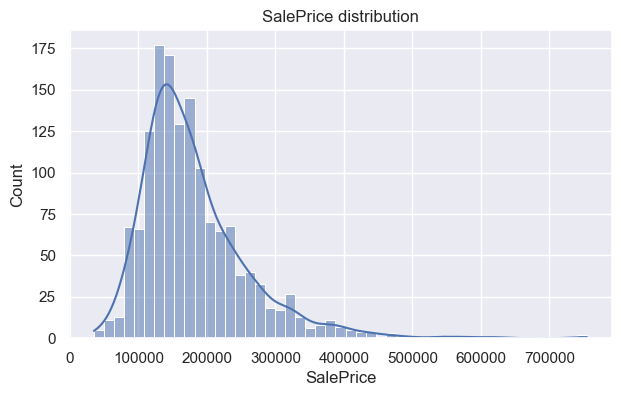

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [63]:
plt.figure(figsize=(7, 4))
sns.histplot(train["SalePrice"], kde=True)
plt.title("SalePrice distribution")
plt.savefig(PLOT_DIR / "hist_SalePrice.png", bbox_inches="tight")
plt.show()

print(train["SalePrice"].describe())

**Reading it:** the bulk of houses are mid-priced, with a long tail of expensive ones, so `SalePrice` is **right-skewed**. This is common for money values and motivates the log transform in Step 6.

### 2.5 Correlation with the target
Correlation measures *linear* association between two numeric columns, from -1 to +1. A high correlation is **not** proof of cause, and a low one does not mean a feature is useless (the relationship could be non-linear).

We show the 10 numeric features most correlated with `SalePrice`, then plot their correlations with each other.

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


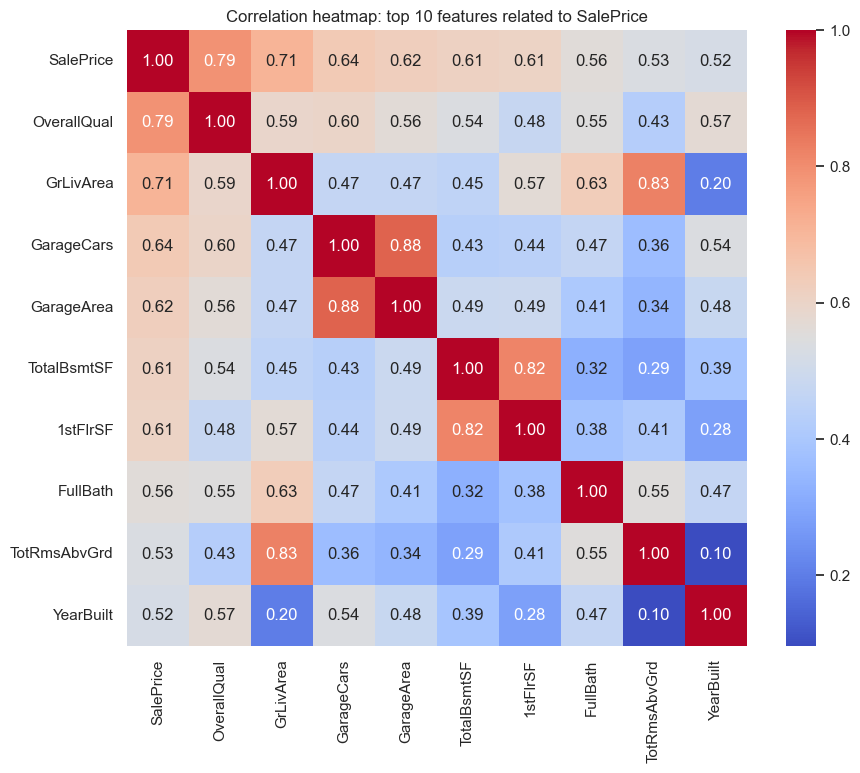

In [64]:
numeric_data = train.select_dtypes(include=np.number).drop(columns=["Id"])
correlations = numeric_data.corr()["SalePrice"].sort_values(ascending=False)
print(correlations.head(11))

top_features = correlations.abs().sort_values(ascending=False).head(10).index

plt.figure(figsize=(10, 8))
sns.heatmap(train[top_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap: top 10 features related to SalePrice")
plt.savefig(PLOT_DIR / "correlation_heatmap.png", bbox_inches="tight")
plt.show()

**What this reveals:**
- `OverallQual` (overall quality) and `GrLivArea` (living area) are usually the strongest predictors of price.
- Several features are strongly correlated **with each other** (e.g. `GarageCars` and `GarageArea`, `TotalBsmtSF` and `1stFlrSF`). This is **multicollinearity**: they carry overlapping information. It matters more for linear models than tree models; we note it for Phase 2.

### 2.6 Important relationships with the price

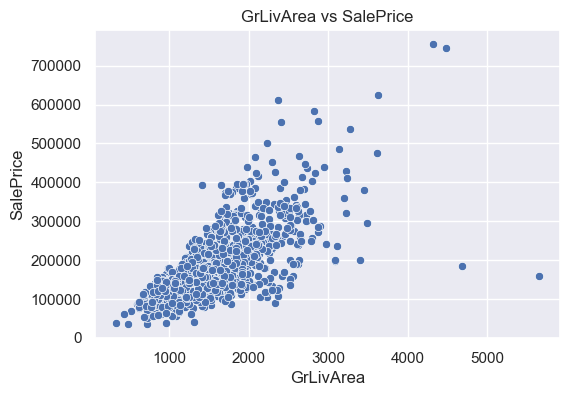

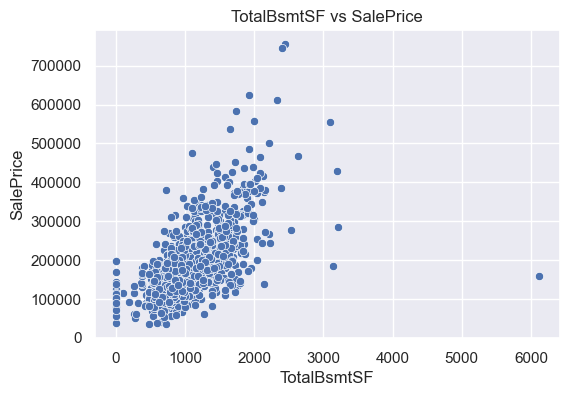

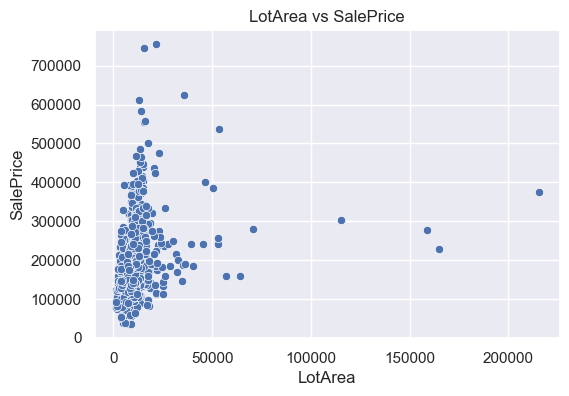

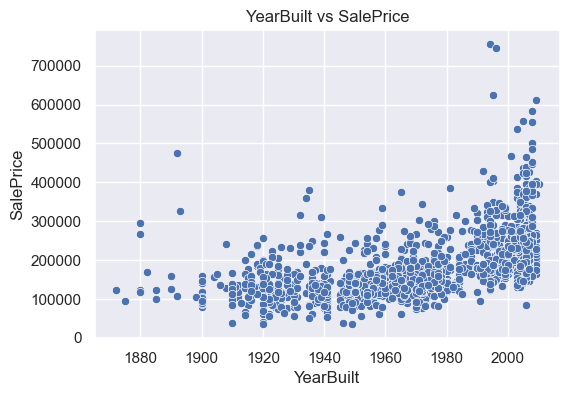

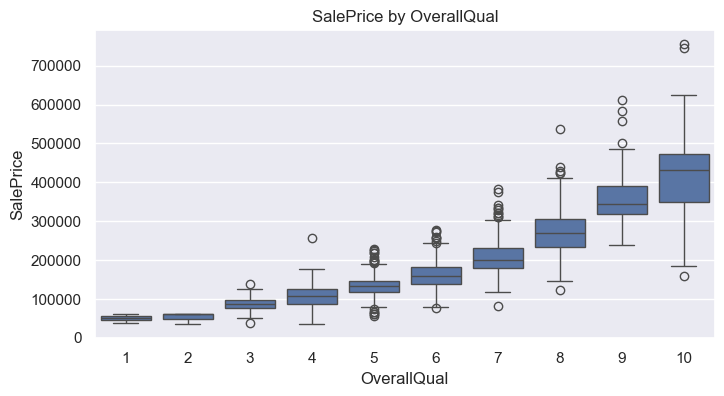

In [65]:
for col in ["GrLivArea", "TotalBsmtSF", "LotArea", "YearBuilt"]:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=train, x=col, y="SalePrice")
    plt.title(col + " vs SalePrice")
    plt.savefig(PLOT_DIR / ("scatter_" + col + ".png"), bbox_inches="tight")
    plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(data=train, x="OverallQual", y="SalePrice")
plt.title("SalePrice by OverallQual")
plt.savefig(PLOT_DIR / "box_OverallQual.png", bbox_inches="tight")
plt.show()

**What these reveal:**
- `GrLivArea` and `TotalBsmtSF` show a clear upward trend: bigger houses cost more.
- In the `GrLivArea` plot, look for a couple of very large houses with a surprisingly **low** price. They break the pattern, and we investigate them in Step 4.
- `OverallQual` shows a steady staircase: higher quality means higher median price, so it will be an important feature.
- `LotArea` has a weak visible trend and is dominated by a few huge lots, so lot size alone is a weak driver.

### 2.7 Categorical features versus the price

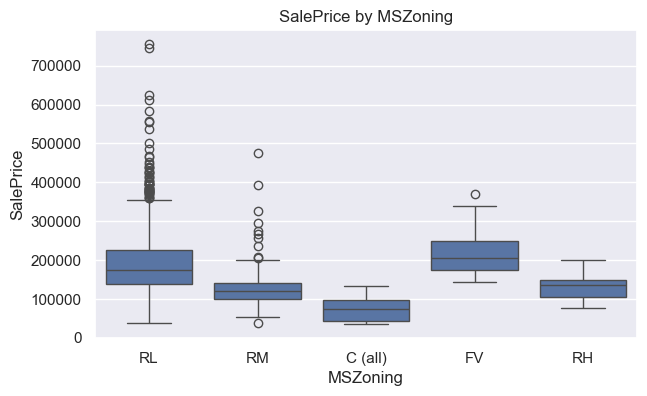

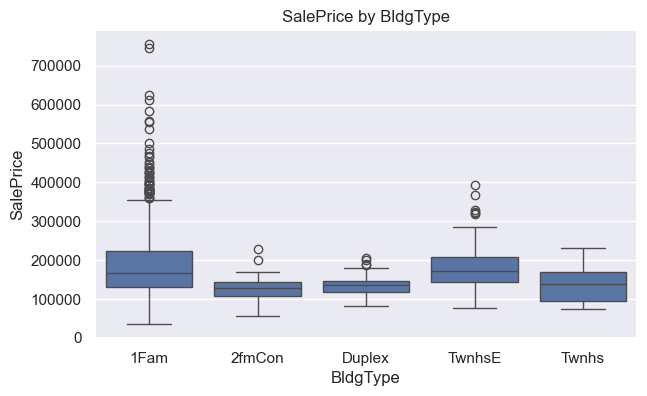

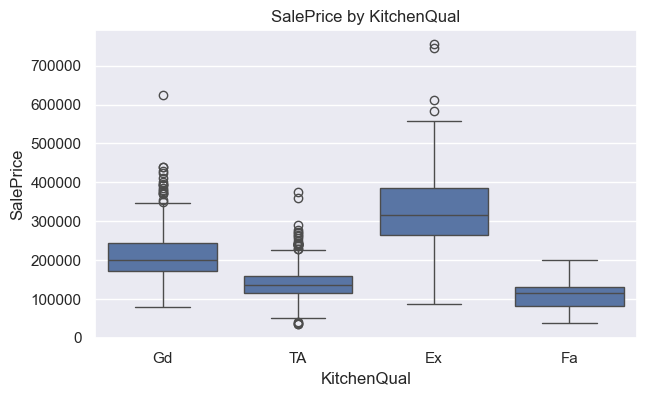

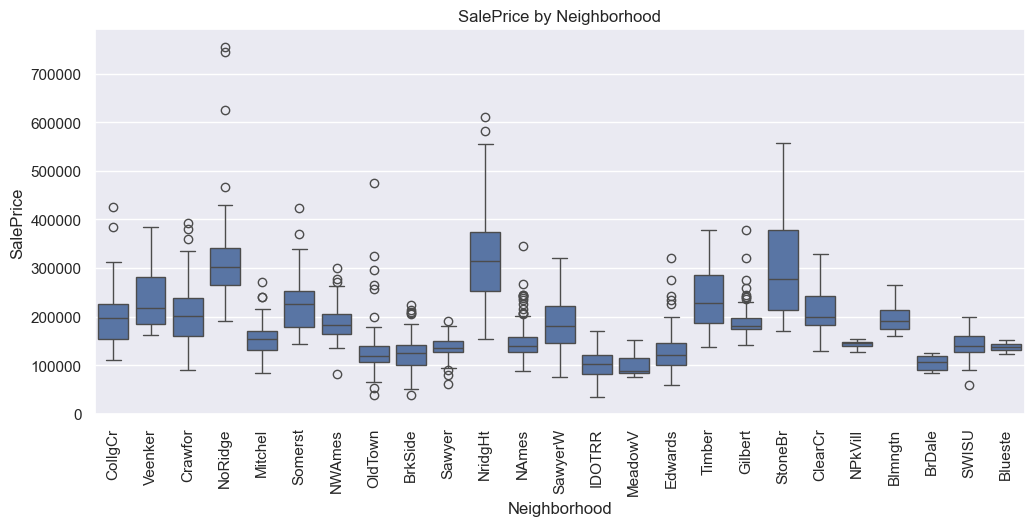

In [66]:
for col in ["MSZoning", "BldgType", "KitchenQual"]:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=train, x=col, y="SalePrice")
    plt.title("SalePrice by " + col)
    plt.savefig(PLOT_DIR / ("box_" + col + ".png"), bbox_inches="tight")
    plt.show()

plt.figure(figsize=(12, 5))
sns.boxplot(data=train, x="Neighborhood", y="SalePrice")
plt.xticks(rotation=90)
plt.title("SalePrice by Neighborhood")
plt.savefig(PLOT_DIR / "box_Neighborhood.png", bbox_inches="tight")
plt.show()

**What these reveal:** price clearly differs by category: better kitchen quality and certain neighborhoods are linked to higher prices. This supports keeping categorical features and one-hot encoding them in Step 8.

> The missing-value report (counts and percentages) is the first part of **Step 3** below, since it leads directly into the treatment decisions.

### Interview explanation for Step 2
> "EDA showed that SalePrice is right-skewed, that quality and living area are the strongest drivers, that several size features are right-skewed with possible outliers, and that many numeric zeros mean 'feature absent' rather than a measurement. Each of those observations drove a later preprocessing decision."

---
# Step 3: Missing-value analysis and treatment

### 3.1 Count and percentage of missing values
We **audit before filling anything**. This report is a key deliverable: it documents the raw state of the data.

,missing_count,missing_percent,dtype
PoolQC,1453,99.52,object
MiscFeature,1406,96.30,object
Alley,1369,93.77,object
Fence,1179,80.75,object
MasVnrType,872,59.73,object
FireplaceQu,690,47.26,object
LotFrontage,259,17.74,float64
GarageType,81,5.55,object
GarageYrBlt,81,5.55,float64
GarageFinish,81,5.55,object


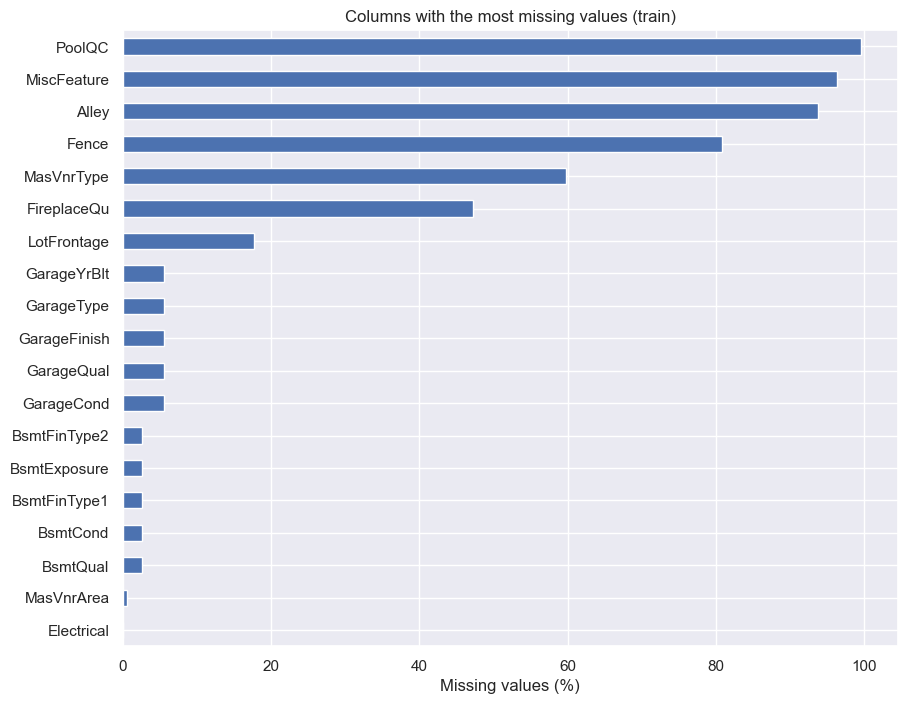

Test set: columns with missing values: 33


In [67]:
missing_counts = train.isna().sum()
missing_report = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percent": (missing_counts / len(train) * 100).round(2),
    "dtype": train.dtypes.astype(str)
})
missing_report = missing_report[missing_report["missing_count"] > 0]
missing_report = missing_report.sort_values("missing_percent", ascending=False)

display(missing_report)
missing_report.to_csv(REPORT_DIR / "01_missing_values_before_cleaning.csv")

plt.figure(figsize=(10, 8))
missing_report.head(30)["missing_percent"].sort_values().plot(kind="barh")
plt.title("Columns with the most missing values (train)")
plt.xlabel("Missing values (%)")
plt.savefig(PLOT_DIR / "missing_values_before_cleaning.png", bbox_inches="tight")
plt.show()

print("Test set: columns with missing values:", int((test.isna().sum() > 0).sum()))

### 3.2 Two very different kinds of "missing"

| Type | Meaning | Example | Right treatment |
|---|---|---|---|
| **Structural missingness** | The feature does not exist, so the blank *is* the answer | No pool → `PoolQC` blank | Fill with `"None"` (text) or `0` (area/count) |
| **Genuinely unknown** | The feature exists but was not recorded | `LotFrontage` blank | Estimate it using statistics from the **training split only** |

> **The famous trap in this dataset:** the data description uses the text `"NA"` to mean "no pool", "no alley", "no garage", and so on. By default `pd.read_csv` converts the text `"NA"` into a real missing value (`NaN`). So most of the columns at the top of the report above are not unknown at all. They are real answers meaning "this house has none".

Replacing *every* missing value with the same number (for example 0 or the median) would be wrong. A missing `PoolQC` is not "average pool quality", and a missing `LotFrontage` is not "zero feet of street".

### 3.3 Decision table

| Column(s) | Fill with | Reason |
|---|---|---|
| `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu` | `"None"` | No pool / misc feature / alley access / fence / fireplace |
| `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond` | `"None"` | No garage |
| `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1`, `BsmtFinType2` | `"None"` | No basement |
| `MasVnrType` | `"None"` | No masonry veneer |
| `GarageCars`, `GarageArea` | `0` | No garage means zero cars and zero area |
| `TotalBsmtSF`, `BsmtFinSF1`, `BsmtFinSF2`, `BsmtUnfSF`, `BsmtFullBath`, `BsmtHalfBath` | `0` | No basement means zero area and zero bathrooms |
| `MasVnrArea` | `0` | No veneer means zero area |
| `LotFrontage` | **median, learned from training split (Step 7)** | Genuinely unknown; the median is robust to outliers |
| `GarageYrBlt` | **not filled; dropped in Step 7** | Missing for no-garage houses (a year cannot be "zero"), contains an impossible value, and duplicates `YearBuilt`; `HasGarage` (Step 5) keeps the useful information |
| Remaining text columns (`Electrical`, `MSZoning`, `KitchenQual`, …) | **most frequent value, learned from training split (Step 7)** | Only a handful of rows, genuinely unknown |

> **Why is it safe to do the "None"/0 fills now, before splitting?** They are fixed, rule-based constants, with no statistics learned from the data. Only fills that *learn* something (median, most frequent) must wait until after the split to avoid leakage.

In [68]:
# Columns where a blank means "feature absent" (text columns -> "None")
structural_text_columns = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "MasVnrType",
]

# Columns where a blank means "feature absent" (numbers -> 0)
structural_zero_columns = [
    "GarageCars", "GarageArea",
    "TotalBsmtSF", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
    "BsmtFullBath", "BsmtHalfBath",
    "MasVnrArea",
]

# Same rule applied to train AND test, so both are treated identically
for df in (train, test):
    for col in structural_text_columns:
        df[col] = df[col].fillna("None")
    for col in structural_zero_columns:
        df[col] = df[col].fillna(0)

transformation_log.append({
    "step": "Structural missing text -> 'None'",
    "details": ", ".join(structural_text_columns),
    "reason": "Blank means the feature is absent (no pool, garage, basement, etc.)"
})
transformation_log.append({
    "step": "Structural missing numbers -> 0",
    "details": ", ".join(structural_zero_columns),
    "reason": "Absent facility has zero area or zero count"
})

print("Missing cells left in train:", int(train.isna().sum().sum()))
print("Missing cells left in test: ", int(test.isna().sum().sum()))

Missing cells left in train: 341
Missing cells left in test:  317


### 3.4 What is still missing, and why we deliberately left it
Everything remaining should be either **genuinely unknown** or intentionally deferred (`GarageYrBlt`, handled in Step 7). Let us verify.

In [69]:
remaining_train = train.isna().sum()
remaining_train = remaining_train[remaining_train > 0].sort_values(ascending=False)
remaining_test = test.isna().sum()
remaining_test = remaining_test[remaining_test > 0].sort_values(ascending=False)

print("Still missing in TRAIN:")
print(remaining_train)
print("\nStill missing in TEST:")
print(remaining_test)

remaining_report = pd.DataFrame({
    "train_missing": remaining_train,
    "test_missing": remaining_test
}).fillna(0).astype(int)
remaining_report.to_csv(REPORT_DIR / "02_missing_values_after_structural_fill.csv")

Still missing in TRAIN:
LotFrontage    259
GarageYrBlt     81
Electrical       1
dtype: int64

Still missing in TEST:
LotFrontage    227
GarageYrBlt     78
MSZoning         4
Utilities        2
Functional       2
Exterior1st      1
Exterior2nd      1
KitchenQual      1
SaleType         1
dtype: int64


### 3.5 Sanity check: did our "feature absent" assumption hold?
A good data scientist tests assumptions. If a house has a garage area above zero but its `GarageFinish` was blank, then that blank is **not** "no garage". It is a genuinely unknown value we just filled with `"None"`. We count such cases.

In [70]:
for name, df in [("train", train), ("test", test)]:
    garage_conflict = ((df["GarageArea"] > 0) & (df["GarageFinish"] == "None")).sum()
    basement_conflict = ((df["TotalBsmtSF"] > 0) & (df["BsmtQual"] == "None")).sum()
    print(name, "| garage area > 0 but GarageFinish 'None':", garage_conflict,
          "| basement area > 0 but BsmtQual 'None':", basement_conflict)

train | garage area > 0 but GarageFinish 'None': 0 | basement area > 0 but BsmtQual 'None': 0
test | garage area > 0 but GarageFinish 'None': 1 | basement area > 0 but BsmtQual 'None': 2


**Reading the result:** only a very small number of rows (if any) conflict. We keep the simple rule because it affects almost nothing, and we note it as a limitation. A more careful project could treat those few rows as unknown and impute them.

**Another honest limitation:** `LotFrontage` has roughly 17–18% missing. Median imputation is simple and defensible. A more advanced alternative is the median *per neighborhood* (frontage tends to be similar within a neighborhood), which could be tested in Phase 2.

### Interview explanation for Step 3
> "I separated structural missingness from unknown values. About a dozen columns were blank because the feature does not exist, for example no pool or no garage, so I filled them with 'None' or 0 using the data description. Truly unknown values like `LotFrontage` are imputed with the median learned only from the training split, so no validation information leaks in."

---
# Step 4: Data quality and outlier analysis

### 4.1 Unusual observation vs. data error

| | Unusual observation | Data error |
|---|---|---|
| **What it is** | A real but rare case | A value that is impossible or recorded wrongly |
| **Example** | A 6,000 sq ft mansion with a very high price | A garage built in the year 2207 |
| **What to do** | Keep it (deleting loses real information and biases the data toward "average" houses) | Correct it, set it to missing, or drop the column, and document why |
| **Grey zone** | A huge house sold at a tiny price: either a special sale (e.g. family transfer, unfinished) or an error. Investigate, flag, and decide with evidence | |

### 4.2 Data type issues
`MSSubClass`, `MoSold`, and `YrSold` are stored as numbers but are really labels or calendar values. We convert all three to categories in Step 7. We wait until then because `YrSold` must stay a number to calculate house age in Step 5.

### 4.3 Invalid values
We already checked negatives and impossible years in Step 1. Summary of what we found and decided:

In [71]:
quality_checks = pd.DataFrame({
    "check": [
        "Negative values in numeric columns",
        "Remodeled before built (train)",
        "Sold before built (train)",
        "Garage built after sale (train)",
        "Impossible garage year (train)",
        "Impossible garage year (test)"
    ],
    "count": [
        int((train[numeric_cols] < 0).sum().sum()),
        int((train["YearRemodAdd"] < train["YearBuilt"]).sum()),
        int((train["YrSold"] < train["YearBuilt"]).sum()),
        int((train["GarageYrBlt"] > train["YrSold"]).sum()),
        int((train["GarageYrBlt"] > latest_sale_year).sum()),
        int((test["GarageYrBlt"] > latest_sale_year).sum())
    ]
})
display(quality_checks)
quality_checks.to_csv(REPORT_DIR / "03_data_quality_checks.csv", index=False)

,check,count
0,Negative values in numeric columns,0
1,Remodeled before built (train),0
2,Sold before built (train),0
3,Garage built after sale (train),0
4,Impossible garage year (train),0
5,Impossible garage year (test),1


**Decision:** `GarageYrBlt` is dropped in Step 7 (reasons in the Step 3 decision table). That removes the impossible value without altering any other row.

### 4.4 The IQR method for detecting outliers
For a numeric feature:
1. `Q1` = 25th percentile, `Q3` = 75th percentile.
2. `IQR = Q3 - Q1` (the spread of the middle 50% of the data).
3. Flag values **below** `Q1 - 1.5 × IQR` or **above** `Q3 + 1.5 × IQR`.

**Advantages:** simple, works on skewed data, does not assume a bell-shaped distribution.
**Limitations:** it flags *candidates*, not errors. On very skewed columns it flags many legitimate values. On columns that are mostly zero (like `PoolArea`) it flags almost every non-zero value, which is meaningless.

First, a count for every numeric column to see where outliers concentrate:

In [72]:
count_rows = []
for col in numeric_cols:
    if col == "Id":
        continue
    values = train[col].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flagged = ((values < lower) | (values > upper)).sum()
    count_rows.append({"feature": col, "flagged_count": int(flagged),
                       "flagged_percent": round(flagged / len(values) * 100, 2)})

outlier_counts = pd.DataFrame(count_rows).sort_values("flagged_count", ascending=False)
display(outlier_counts.head(15))
outlier_counts.to_csv(REPORT_DIR / "04_outlier_counts_all_numeric.csv", index=False)

,feature,flagged_count,flagged_percent
29,EnclosedPorch,208,14.25
9,BsmtFinSF2,167,11.44
4,OverallCond,125,8.56
31,ScreenPorch,116,7.95
0,MSSubClass,103,7.05
7,MasVnrArea,98,6.71
1,LotFrontage,88,7.33
17,BsmtHalfBath,82,5.62
28,OpenPorchSF,77,5.27
2,LotArea,69,4.73


Now a detailed look at the features that matter most for pricing. We save the exact flagged rows so you can inspect them. **Nothing is removed.**

In [73]:
outlier_columns = ["LotArea", "LotFrontage", "GrLivArea", "TotalBsmtSF", "GarageArea", "SalePrice"]

summary_rows = []
flag_rows = []

for col in outlier_columns:
    values = train[col].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    is_outlier = (train[col] < lower) | (train[col] > upper)

    summary_rows.append({
        "feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_bound": lower, "upper_bound": upper,
        "flagged_count": int(is_outlier.sum())
    })

    for idx in train.index[is_outlier]:
        flag_rows.append({
            "Id": train.loc[idx, "Id"], "feature": col,
            "value": train.loc[idx, col],
            "lower_bound": lower, "upper_bound": upper
        })

outlier_summary = pd.DataFrame(summary_rows)
outlier_flags = pd.DataFrame(flag_rows)

display(outlier_summary)
outlier_summary.to_csv(REPORT_DIR / "05_outlier_summary_key_features.csv", index=False)
outlier_flags.to_csv(REPORT_DIR / "06_outlier_rows_flagged_for_review.csv", index=False)
print("Flagged rows saved for review. No observations were removed.")

,feature,Q1,Q3,IQR,lower_bound,upper_bound,flagged_count
0,LotArea,7553.50,11601.50,4048.00,1481.500,17673.500,69
1,LotFrontage,59.00,80.00,21.00,27.500,111.500,88
2,GrLivArea,1129.50,1776.75,647.25,158.625,2747.625,31
3,TotalBsmtSF,795.75,1298.25,502.50,42.000,2052.000,61
4,GarageArea,334.50,576.00,241.50,-27.750,938.250,21
5,SalePrice,129975.00,214000.00,84025.00,3937.500,340037.500,61


Flagged rows saved for review. No observations were removed.


### 4.5 Visualizing outliers
Box plots show the IQR rule visually: the box is Q1 to Q3, and the dots beyond the whiskers are the flagged values.

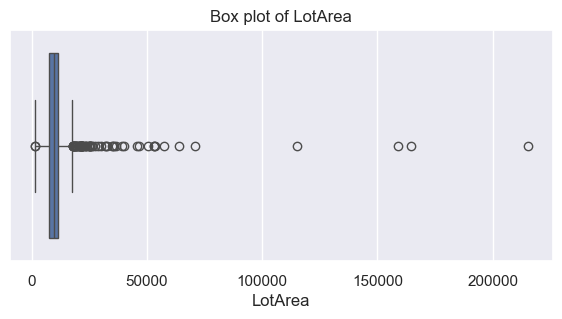

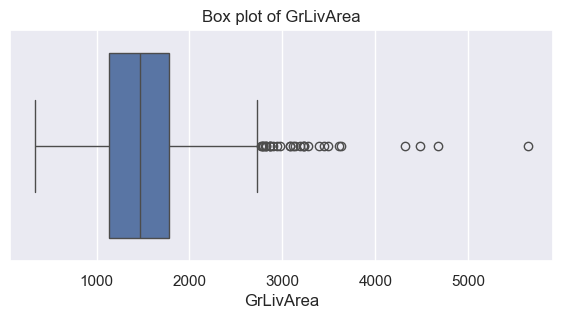

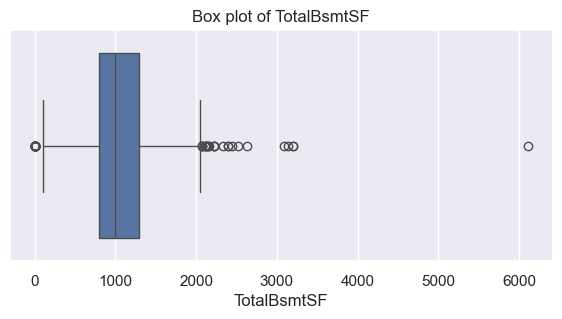

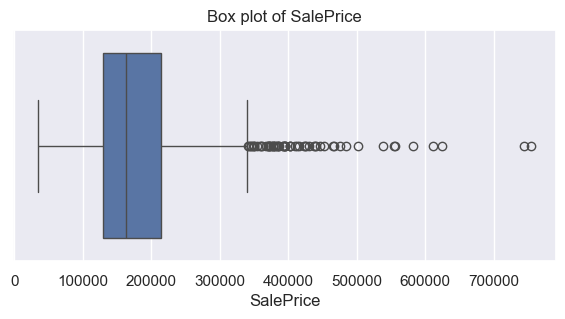

In [74]:
for col in ["LotArea", "GrLivArea", "TotalBsmtSF", "SalePrice"]:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=train[col])
    plt.title("Box plot of " + col)
    plt.savefig(PLOT_DIR / ("outlier_box_" + col + ".png"), bbox_inches="tight")
    plt.show()

### 4.6 Investigating the suspicious houses
The most important outlier question in this dataset is: **very large houses with a surprisingly low price**. Those do not follow the general pattern "bigger house → higher price".

Number of very large houses sold cheaply: 2


,Id,GrLivArea,TotalBsmtSF,OverallQual,SaleCondition,SalePrice
523,524,4676,3138,10,Partial,184750
1298,1299,5642,6110,10,Partial,160000


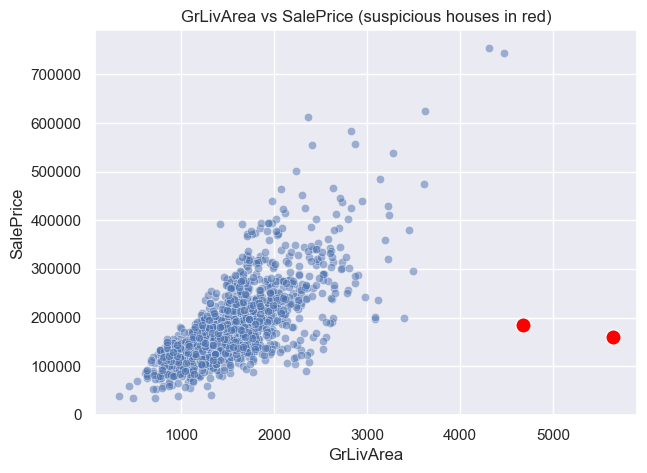

In [75]:
suspicious = train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)]
print("Number of very large houses sold cheaply:", len(suspicious))
display(suspicious[["Id", "GrLivArea", "TotalBsmtSF", "OverallQual", "SaleCondition", "SalePrice"]])

# Highlight them on the scatter plot
plt.figure(figsize=(7, 5))
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", alpha=0.5)
sns.scatterplot(data=suspicious, x="GrLivArea", y="SalePrice", color="red", s=120)
plt.title("GrLivArea vs SalePrice (suspicious houses in red)")
plt.savefig(PLOT_DIR / "suspicious_houses.png", bbox_inches="tight")
plt.show()

suspicious[["Id", "GrLivArea", "SalePrice", "SaleCondition"]].to_csv(
    REPORT_DIR / "07_suspicious_large_cheap_houses.csv", index=False)

**How to read this:** check the `SaleCondition` column. A value such as `Partial` means the house was sold before it was finished, so its price is low for its size. That is a real explanation, not an error in the *measurement*, but these houses can still mislead a model about "what a large house is worth".

**Decision (for Phase 1):** keep every row and just **flag** these houses. Whether to exclude them when training is a *modeling* decision to make in Phase 2, with a written reason and a comparison of results with and without them.

### Interview explanation for Step 4
> "I used the IQR rule to flag outliers but did not delete any. I separated impossible values, like a garage year of 2207, which are errors, from rare-but-real observations, like expensive houses. I investigated two very large, low-priced houses, found a likely explanation in `SaleCondition`, and flagged them for the modeling phase instead of silently removing them."

In [76]:
transformation_log.append({
    "step": "Outliers flagged, not removed",
    "details": "IQR rule on LotArea, LotFrontage, GrLivArea, TotalBsmtSF, GarageArea, SalePrice",
    "reason": "Large or expensive houses can be legitimate; removal decided in modeling phase"
})

---
# Step 5: Feature engineering

**What it is:** creating new columns by combining existing ones into measurements that are more directly useful for pricing. Buyers think in "total square feet" and "number of bathrooms", not in 5 separate floor-area columns.

**Leakage rule:** we only use information known **at the time of sale**: physical features, the build year, the remodel year, and the sale year. We never use `SalePrice` to build a feature.

### 5.1 Formulas

| New feature | Formula | Why |
|---|---|---|
| `TotalSF` | `TotalBsmtSF + 1stFlrSF + 2ndFlrSF` | One number for total interior area |
| `TotalBathrooms` | `FullBath + 0.5×HalfBath + BsmtFullBath + 0.5×BsmtHalfBath` | A half bath is worth about half a full bath |
| `TotalPorchSF` | `WoodDeckSF + OpenPorchSF + EnclosedPorch + 3SsnPorch + ScreenPorch` | Total outdoor living area |
| `HouseAgeAtSale` | `YrSold - YearBuilt` | Older houses usually sell for less |
| `YearsSinceRemodel` | `YrSold - YearRemodAdd` | A recent remodel adds value |
| `HasPool` | `1 if PoolArea > 0 else 0` | Pools are very rare, so a yes/no flag is more useful than an area |
| `HasGarage` | `1 if GarageArea > 0 else 0` | Keeps the garage information after dropping `GarageYrBlt` |
| `HasFireplace` | `1 if Fireplaces > 0 else 0` | Simple amenity indicator |

The function below is applied identically to train and test.

In [77]:
def add_features(df):
    df = df.copy()

    # Total interior area = basement + 1st floor + 2nd floor
    df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]

    # Half bathrooms count as 0.5
    df["TotalBathrooms"] = (df["FullBath"] + 0.5 * df["HalfBath"]
                            + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"])

    # All outdoor areas added together
    df["TotalPorchSF"] = (df["WoodDeckSF"] + df["OpenPorchSF"] + df["EnclosedPorch"]
                          + df["3SsnPorch"] + df["ScreenPorch"])

    # Ages measured at the time of sale
    df["HouseAgeAtSale"] = df["YrSold"] - df["YearBuilt"]
    df["YearsSinceRemodel"] = df["YrSold"] - df["YearRemodAdd"]

    # Yes/no amenity indicators (1 = yes, 0 = no)
    df["HasPool"] = (df["PoolArea"] > 0).astype(int)
    df["HasGarage"] = (df["GarageArea"] > 0).astype(int)
    df["HasFireplace"] = (df["Fireplaces"] > 0).astype(int)

    return df


train = add_features(train)
test = add_features(test)

engineered_cols = ["TotalSF", "TotalBathrooms", "TotalPorchSF", "HouseAgeAtSale",
                   "YearsSinceRemodel", "HasPool", "HasGarage", "HasFireplace"]
display(train[["Id"] + engineered_cols].head())

,Id,TotalSF,TotalBathrooms,TotalPorchSF,HouseAgeAtSale,YearsSinceRemodel,HasPool,HasGarage,HasFireplace
0,1,2566,3.5,61,5,5,0,1,0
1,2,2524,2.5,298,31,31,0,1,1
2,3,2706,3.5,42,7,6,0,1,1
3,4,2473,2.0,307,91,36,0,1,1
4,5,3343,3.5,276,8,8,0,1,1


### 5.2 Check that the derived features are valid
We never trust a formula without checking its output. Things that should be true: areas are positive, ages are not negative, and bathroom counts are sensible.

In [78]:
display(train[engineered_cols].describe().T)

for name, df in [("train", train), ("test", test)]:
    print(name,
          "| negative house age:", int((df["HouseAgeAtSale"] < 0).sum()),
          "| negative years since remodel:", int((df["YearsSinceRemodel"] < 0).sum()),
          "| TotalSF <= 0:", int((df["TotalSF"] <= 0).sum()),
          "| missing in new features:", int(df[engineered_cols].isna().sum().sum()))

,count,mean,std,min,25%,50%,75%,max
TotalSF,1460.0,2567.048630,821.714421,334.0,2009.5,2474.0,3004.0,11752.0
TotalBathrooms,1460.0,2.210616,0.785399,1.0,2.0,2.0,2.5,6.0
TotalPorchSF,1460.0,181.329452,156.656097,0.0,45.0,164.0,266.0,1027.0
HouseAgeAtSale,1460.0,36.547945,30.250152,0.0,8.0,35.0,54.0,136.0
YearsSinceRemodel,1460.0,22.950000,20.640653,-1.0,4.0,14.0,41.0,60.0
HasPool,1460.0,0.004795,0.069100,0.0,0.0,0.0,0.0,1.0
HasGarage,1460.0,0.944521,0.228992,0.0,1.0,1.0,1.0,1.0
HasFireplace,1460.0,0.527397,0.499420,0.0,0.0,1.0,1.0,1.0


train | negative house age: 0 | negative years since remodel: 1 | TotalSF <= 0: 0 | missing in new features: 0
test | negative house age: 1 | negative years since remodel: 2 | TotalSF <= 0: 0 | missing in new features: 0


**If you see a few ages of -1:** the house was probably sold in the year it was completed or shortly before (a sale of a house still under construction). That is plausible, not a corrupt row. An age cannot be negative, so we set those values to 0 ("brand new") instead of deleting the house.

In [79]:
for df in (train, test):
    df["HouseAgeAtSale"] = df["HouseAgeAtSale"].clip(lower=0)
    df["YearsSinceRemodel"] = df["YearsSinceRemodel"].clip(lower=0)

print("Negative ages left in train:", int((train["HouseAgeAtSale"] < 0).sum() + (train["YearsSinceRemodel"] < 0).sum()))
print("Negative ages left in test: ", int((test["HouseAgeAtSale"] < 0).sum() + (test["YearsSinceRemodel"] < 0).sum()))

transformation_log.append({
    "step": "Engineered 8 features",
    "details": ", ".join(engineered_cols),
    "reason": "Combine related columns into measurements closer to how buyers think; uses only information known at sale time"
})
transformation_log.append({
    "step": "Clipped negative ages to 0",
    "details": "HouseAgeAtSale, YearsSinceRemodel",
    "reason": "A house sold just before completion has age -1; age cannot be negative, row kept"
})

Negative ages left in train: 0
Negative ages left in test:  0


### 5.3 Do the new features look useful? (EDA only, not modeling)
We compare correlation with `SalePrice` for the new features. This is **descriptive analysis** on the training data, not model evaluation.

TotalSF              0.782
TotalBathrooms       0.632
HasFireplace         0.472
TotalPorchSF         0.391
HasGarage            0.237
HasPool              0.094
YearsSinceRemodel   -0.509
HouseAgeAtSale      -0.523
Name: SalePrice, dtype: float64


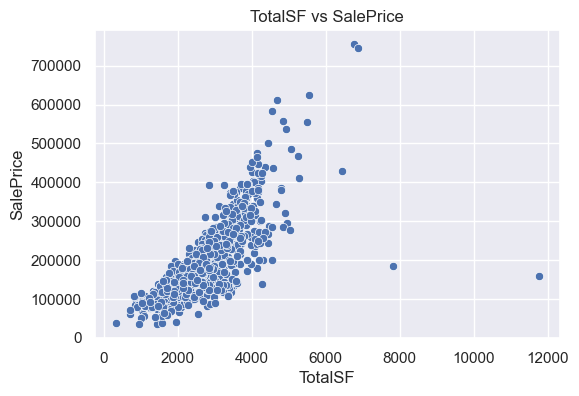

In [80]:
new_feature_corr = train[engineered_cols + ["SalePrice"]].corr()["SalePrice"].drop("SalePrice")
print(new_feature_corr.sort_values(ascending=False).round(3))

plt.figure(figsize=(6, 4))
sns.scatterplot(data=train, x="TotalSF", y="SalePrice")
plt.title("TotalSF vs SalePrice")
plt.savefig(PLOT_DIR / "scatter_TotalSF.png", bbox_inches="tight")
plt.show()

**Reading it:** `TotalSF` and `TotalBathrooms` usually correlate strongly and positively with price, and `HouseAgeAtSale` negatively (older → cheaper). Whether they truly **improve a model** can only be tested in Phase 2.

**Limitation:** `TotalSF` overlaps with its source columns (multicollinearity). That matters for linear models, and we may drop the originals later.

### Interview explanation for Step 5
> "I engineered features that match how buyers think: total square footage, total bathrooms with half baths counted as 0.5, total porch area, age at sale, years since remodel, and amenity flags. Every one uses only information available at sale time, I verified there were no negative areas or ages, and I applied identical code to train and test so the columns match."

---
# Step 6: Target variable analysis

### 6.1 Is `SalePrice` skewed?
- **Skewness** measures asymmetry: 0 is symmetric, a positive value means a long right tail.
- **Kurtosis** measures how heavy the tails are: higher means more extreme values.

In [81]:
print("SalePrice skewness:", round(train["SalePrice"].skew(), 3))
print("SalePrice kurtosis:", round(train["SalePrice"].kurt(), 3))

q1 = train["SalePrice"].quantile(0.25)
q3 = train["SalePrice"].quantile(0.75)
iqr = q3 - q1
price_upper = q3 + 1.5 * iqr
print("\nIQR upper bound for SalePrice:", round(price_upper))
print("Houses above it:", int((train["SalePrice"] > price_upper).sum()))

SalePrice skewness: 1.883
SalePrice kurtosis: 6.536

IQR upper bound for SalePrice: 340038
Houses above it: 61


### 6.2 When is `log1p(SalePrice)` useful?
`log1p(x)` computes `log(1 + x)`. (The `+1` makes it safe if a value is 0.) Taking the log:
- **Compresses the long right tail**, so expensive houses stop dominating.
- Makes the distribution closer to symmetric (bell-shaped), which suits many regression methods.
- Turns **multiplicative** differences into additive ones. A 10% price gap becomes roughly the same size at 100,000 dollars and at 500,000 dollars. This is natural for prices.
- It matches the Kaggle competition metric, which measures error on the **log** of the price.

**Limitations:** predictions must be converted back with `expm1` (the exact inverse of `log1p`) before reporting real prices. Tree-based models do not need this transform because they do not assume a shape.

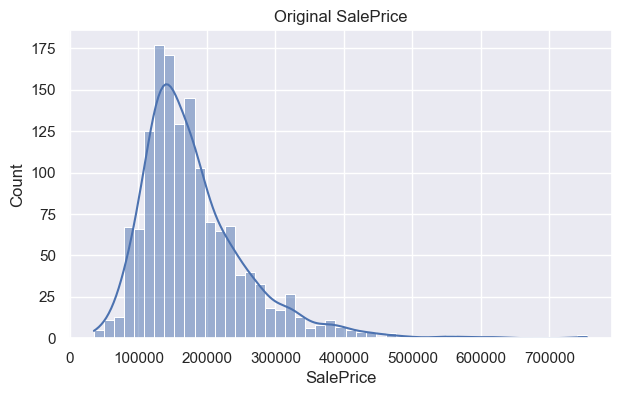

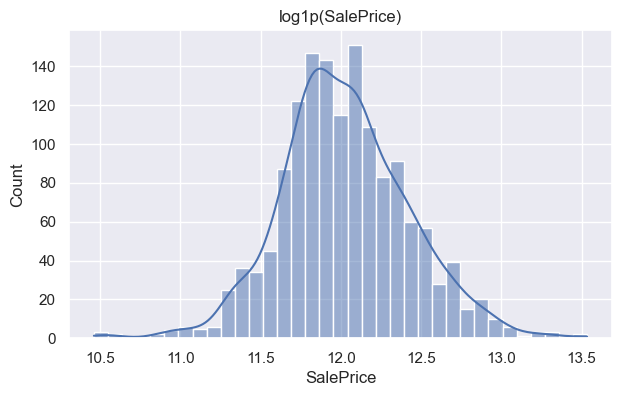

Skewness BEFORE log1p: 1.883
Skewness AFTER  log1p: 0.121


In [82]:
plt.figure(figsize=(7, 4))
sns.histplot(train["SalePrice"], kde=True)
plt.title("Original SalePrice")
plt.savefig(PLOT_DIR / "target_original.png", bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(np.log1p(train["SalePrice"]), kde=True)
plt.title("log1p(SalePrice)")
plt.savefig(PLOT_DIR / "target_log1p.png", bbox_inches="tight")
plt.show()

print("Skewness BEFORE log1p:", round(train["SalePrice"].skew(), 3))
print("Skewness AFTER  log1p:", round(np.log1p(train["SalePrice"]).skew(), 3))

### 6.3 Keep the two versions of the target clearly separate
- `y_price` = the **original** price in dollars.
- `y_log` = `log1p(SalePrice)`, the **transformed** target for modeling.

`test.csv` has **no** `SalePrice`, so there is nothing to transform there. We never create or fill a target for the test set.

In [83]:
y_price = train["SalePrice"].astype(float)   # ORIGINAL target (dollars)
y_log = np.log1p(y_price)                    # TRANSFORMED target

print("Original target example:    ", y_price.iloc[0])
print("Transformed target example: ", round(y_log.iloc[0], 4))
print("Converted back with expm1:  ", round(np.expm1(y_log.iloc[0]), 2))
print("\n'SalePrice' in test:", "SalePrice" in test.columns, "(must be False)")

transformation_log.append({
    "step": "Created log1p(SalePrice) target",
    "details": "y_log = log1p(y_price); original kept as y_price; not applied to test",
    "reason": "SalePrice is right-skewed; log makes it more symmetric and matches the Kaggle metric"
})

Original target example:     208500.0
Transformed target example:  12.2477
Converted back with expm1:   208500.0

'SalePrice' in test: False (must be False)


### Interview explanation for Step 6
> "SalePrice is right-skewed, so I created `log1p(SalePrice)` as a separate target while keeping the original in dollars. The log reduces the influence of very expensive houses and matches the competition's log-based error. Predictions will be converted back with `expm1`. The test set has no target, so no transformation is applied to it."

---
# Step 7: Leakage-safe data preparation

### 7.1 What is data leakage?
**Data leakage** means information from outside the training data (validation or test data, or the target itself) sneaks into the model-building process. It makes results look better than they will be on truly new houses.

A subtle example: if we compute the **median** of `LotFrontage` using *all* rows, including validation rows, then the validation set has influenced our preprocessing. So the rule is:

> **Split first. Learn (fit) every statistic on the training part only. Then apply (transform) to validation and test.**

### 7.2 Separate predictors, target, and ID
- `SalePrice` (target) and `Id` (row label) are removed from the predictor table.
- `GarageYrBlt` is dropped (reasons in Steps 3 and 4).
- `MSSubClass`, `MoSold`, `YrSold` are converted to text categories. `MSSubClass=60` is not "three times" `MSSubClass=20`, and month 12 is not "twelve times" month 1, so these must be encoded as labels, not treated as quantities. (We delayed this until now because Step 5 needed `YrSold` as a number.)
- We keep `test_ids` so Kaggle predictions can be matched to houses later.

In [84]:
train_ids = train["Id"].copy()
test_ids = test["Id"].copy()

# Predictors only: no target, no ID, no GarageYrBlt
X = train.drop(columns=["SalePrice", "Id", "GarageYrBlt"])
X_test = test.drop(columns=["Id", "GarageYrBlt"])

# Code-like numbers become text categories
code_like_columns = ["MSSubClass", "MoSold", "YrSold"]
for col in code_like_columns:
    X[col] = X[col].astype(str)
    X_test[col] = X_test[col].astype(str)

# Safety checks
assert "SalePrice" not in X.columns
assert "Id" not in X.columns and "Id" not in X_test.columns
assert list(X.columns) == list(X_test.columns), "Train and test feature columns differ."

print("Predictor table (train):", X.shape)
print("Predictor table (test): ", X_test.shape)

transformation_log.append({
    "step": "Dropped GarageYrBlt",
    "details": "Removed from predictors",
    "reason": "Missing for no-garage houses, contains impossible year, duplicates YearBuilt; HasGarage keeps the information"
})
transformation_log.append({
    "step": "Converted MSSubClass, MoSold, YrSold to categories",
    "details": "numbers -> text labels",
    "reason": "They are codes/labels, not quantities"
})
transformation_log.append({
    "step": "Removed Id and SalePrice from predictors",
    "details": "Id kept separately for tracking; target kept as y_price / y_log",
    "reason": "Id is not informative; the target must never be a feature"
})

Predictor table (train): (1460, 86)
Predictor table (test):  (1459, 86)


### 7.3 Split into training and validation sets **before** fitting anything
- **Training set (80%)**: used to learn medians, most-frequent values, category lists, and scaling statistics.
- **Validation set (20%)**: held back to check Phase 2 models on houses they did not learn from.
- **Kaggle test set**: has no prices; only transformed, never used for fitting.

`random_state=42` fixes the shuffle, so everyone running this notebook gets the same split.

In [85]:
X_train, X_valid, y_train_log, y_valid_log = train_test_split(
    X, y_log, test_size=0.20, random_state=RANDOM_STATE
)

print("Training rows:  ", X_train.shape[0])
print("Validation rows:", X_valid.shape[0])
print("Kaggle test rows:", X_test.shape[0])

# The split should keep similar price levels in both parts
print("\nMean log price, training:  ", round(y_train_log.mean(), 4))
print("Mean log price, validation:", round(y_valid_log.mean(), 4))

transformation_log.append({
    "step": "Train/validation split 80/20 (random_state=42)",
    "details": "Done BEFORE fitting any imputer, encoder or scaler",
    "reason": "Prevents validation information from influencing learned preprocessing"
})

Training rows:   1168
Validation rows: 292
Kaggle test rows: 1459

Mean log price, training:   12.0307
Mean log price, validation: 11.9977


### 7.4 Build the preprocessing pipelines
A scikit-learn **`Pipeline`** chains steps so they always run in the same order. A **`ColumnTransformer`** sends different columns through different pipelines. Together they make preprocessing **repeatable** and prevent the classic mistake of forgetting a step on the test data.

| Column type | Step 1 | Step 2 |
|---|---|---|
| **Numeric** | Fill missing with the **median** | **Scale** (standardize) |
| **Categorical** | Fill missing with the **most frequent value** | **One-hot encode** |

**Why the median?** It is not distorted by outliers (unlike the mean). Good for skewed columns like `LotFrontage`.

**Why most-frequent for categories?** The remaining missing text values are genuinely unknown (a few rows in `Electrical`, `MSZoning`, `KitchenQual`, …), so the most common label is the most reasonable guess. Inventing a new "Missing" label for one or two rows would create a column the model can almost never learn from.

In [86]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:    ", len(numeric_features))
print("Categorical features:", len(categorical_features))

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    verbose_feature_names_out=False
)

print("\nPipelines built (nothing has been fitted yet).")

Numeric features:     40
Categorical features: 46

Pipelines built (nothing has been fitted yet).


### Interview explanation for Step 7
> "I removed the target and ID from the features, then split into training and validation sets **before** fitting any imputer, encoder, or scaler, so no validation information could leak into preprocessing. I used `Pipeline` and `ColumnTransformer` so exactly the same learned steps are applied to validation and Kaggle test data."

---
# Step 8: Encoding and scaling

### 8.1 One-hot encoding for categorical variables
Models need numbers, not text. **One-hot encoding** turns a column like `KitchenQual` (Ex, Gd, TA, Fa) into one 0/1 column per category (`KitchenQual_Ex`, `KitchenQual_Gd`, …).

**Why not just number them 1, 2, 3?** For unordered categories like `Neighborhood`, numbers would invent a fake order (is "NAmes" bigger than "CollgCr"?). One-hot avoids that.

**Advantages:** no false ordering, easy to explain.
**Limitations:** it creates many columns, and a high-cardinality column like `Neighborhood` (25 values) adds 25 of them. Quality ratings such as `ExterQual` (Ex > Gd > TA > Fa) *are* ordered, so an ordinal encoding could be tested in Phase 2.

### 8.2 Handling unseen categories safely
The test file may contain a category that never appears in the training split (or a category may be rare). We use `handle_unknown="ignore"`, which encodes an unseen category as all zeros instead of crashing. Let us see whether this actually happens here:

In [87]:
found_unseen = False
for col in categorical_features:
    seen_in_training = set(X_train[col].dropna().unique())
    for name, frame in [("validation", X_valid), ("test", X_test)]:
        unseen = set(frame[col].dropna().unique()) - seen_in_training
        if len(unseen) > 0:
            print(col, "| categories in", name, "never seen in training:", sorted(unseen))
            found_unseen = True

if not found_unseen:
    print("No unseen categories found.")

MSSubClass | categories in test never seen in training: ['150']
RoofMatl | categories in validation never seen in training: ['Membran']
Electrical | categories in validation never seen in training: ['Mix']


If anything is printed above, that is exactly why `handle_unknown="ignore"` matters: those rows get all zeros for that column's dummy variables instead of causing an error.

### 8.3 Scaling numeric features
`StandardScaler` converts each numeric column to **mean 0 and standard deviation 1** using `(value - mean) / std`. This is learned from the **training split only**.

**Why scale?** Features live on very different scales (`LotArea` in the thousands vs `OverallQual` from 1 to 10). Models that use distances or gradient descent (linear regression with regularisation, KNN, SVM, neural networks) are dominated by large-valued columns unless we scale.

**Why tree-based models do not need it:** decision trees, random forests, and gradient boosting split on thresholds (`GrLivArea > 1500?`). Multiplying or shifting a column does not change which rows land on each side, so scaling has no effect on trees. We scale here to keep the matrices ready for any model type; in Phase 2 we can skip it for tree models.

> We scale only the numeric columns, not the 0/1 dummy columns.

### 8.4 Fit on training only, transform everything
- `fit_transform(X_train)`: **learns** medians, most-frequent values, categories, and scaling statistics, then applies them.
- `transform(X_valid)` and `transform(X_test)`: applies the **already-learned** values. No re-learning.

In [88]:
X_train_array = preprocessor.fit_transform(X_train)   # fit on training only
X_valid_array = preprocessor.transform(X_valid)       # transform only
X_test_array = preprocessor.transform(X_test)         # transform only

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(X_train_array, columns=feature_names, index=X_train.index)
X_valid_processed = pd.DataFrame(X_valid_array, columns=feature_names, index=X_valid.index)
X_test_processed = pd.DataFrame(X_test_array, columns=feature_names, index=X_test.index)

print("Processed training shape:  ", X_train_processed.shape)
print("Processed validation shape:", X_valid_processed.shape)
print("Processed test shape:      ", X_test_processed.shape)
print("Features before encoding:", X_train.shape[1], "| after encoding:", len(feature_names))

display(X_train_processed.head())

transformation_log.append({
    "step": "Median imputation + StandardScaler on numeric features",
    "details": "Fitted on training split only",
    "reason": "Median resists outliers; scaling puts features on a comparable scale"
})
transformation_log.append({
    "step": "Most-frequent imputation + one-hot encoding on categorical features",
    "details": "handle_unknown='ignore'; fitted on training split only",
    "reason": "Unknown labels get the common value; one-hot avoids fake ordering; unseen categories do not crash"
})

Processed training shape:   (1168, 336)
Processed validation shape: (292, 336)
Processed test shape:       (1459, 336)
Features before encoding: 86 | after encoding: 336


,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,TotalSF,TotalBathrooms,TotalPorchSF,HouseAgeAtSale,YearsSinceRemodel,HasPool,HasGarage,HasFireplace,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_40,MSSubClass_45,MSSubClass_50,MSSubClass_60,...,GarageCond_TA,PavedDrive_N,PavedDrive_P,PavedDrive_Y,PoolQC_Ex,PoolQC_Fa,PoolQC_Gd,PoolQC_None,Fence_GdPrv,Fence_GdWo,Fence_MnPrv,Fence_MnWw,Fence_None,MiscFeature_Gar2,MiscFeature_None,MiscFeature_Othr,MiscFeature_Shed,MiscFeature_TenC,MoSold_1,MoSold_10,MoSold_11,MoSold_12,MoSold_2,MoSold_3,MoSold_4,MoSold_5,MoSold_6,MoSold_7,MoSold_8,MoSold_9,YrSold_2006,YrSold_2007,YrSold_2008,YrSold_2009,YrSold_2010,SaleType_COD,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
254,-0.012468,-0.212896,-0.820445,0.372217,-0.455469,-1.346063,-0.597889,1.037269,-0.285504,-0.400282,0.572612,0.374235,-0.801923,-0.118999,-0.407093,1.105320,-0.24287,-1.055566,-0.764098,0.136218,-0.212757,-0.964566,-0.958592,-1.056544,-0.863837,1.188402,-0.714352,-0.351921,-0.121008,-0.275838,-0.070993,-0.09274,0.054233,-0.285144,0.393730,0.526141,1.452706,-0.071858,0.240772,-1.065497,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1066,-0.502357,-0.265245,-0.088934,1.268609,0.718609,0.439214,-0.597889,-0.971996,-0.285504,0.511920,-0.596547,-0.958202,0.955088,-0.118999,0.083170,-0.818694,-0.24287,0.773664,1.236947,0.136218,-0.212757,0.270755,0.592150,0.295092,-0.456264,-0.740157,-0.138015,-0.351921,-0.121008,-0.275838,-0.070993,-0.09274,-0.260035,0.356567,-0.910109,-0.679464,-0.382622,-0.071858,0.240772,0.938529,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
638,-0.146074,-0.177841,-0.820445,1.268609,-1.988293,-1.683818,-0.597889,-0.971996,-0.285504,0.505196,-0.603357,-0.965964,-0.801923,-0.118999,-1.395250,-0.818694,-0.24287,-1.055566,-0.764098,-1.106774,-0.212757,-1.582227,-0.958592,-2.408179,-2.257169,1.790113,-0.714352,2.290826,-0.121008,-0.275838,-0.070993,-0.09274,-1.207714,-1.568564,1.896250,1.992419,1.694197,-0.071858,-4.153312,-1.065497,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
799,-0.457822,-0.324474,-0.820445,1.268609,-1.107734,-1.683818,0.861522,0.267995,-0.285504,-0.915776,-0.750921,-0.487321,0.989227,-0.118999,0.458975,1.105320,-0.24287,-1.055566,1.236947,0.136218,-0.212757,0.270755,2.142892,-1.056544,-1.119755,-0.740157,-0.714352,3.902257,-0.121008,-0.275838,-0.070993,-0.09274,-0.102901,0.356567,0.480653,1.080068,1.645898,-0.071858,0.240772,0.938529,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
380,-0.903175,-0.529035,-0.820445,0.372217,-1.531707,-1.683818,-0.597889,-0.496920,-0.285504,0.532091,-0.081209,-0.370895,0.711564,-0.118999,0.312087,-0.818694,-0.24287,0.773664,-0.764098,0.136218,-0.212

### 8.5 Proof that scaling was learned from the training set only
After scaling, the training numeric columns should have mean ≈ 0 and standard deviation ≈ 1. The validation columns will be *close* to that but **not exactly**, because they used the training statistics. That small difference is the evidence that no leakage occurred.

In [89]:
print("Training numeric columns, average of column means:     ",
      round(X_train_processed[numeric_features].mean().mean(), 4))
print("Validation numeric columns, average of column means:   ",
      round(X_valid_processed[numeric_features].mean().mean(), 4))
print("Training numeric columns, average of column std:       ",
      round(X_train_processed[numeric_features].std().mean(), 4))
print("Validation numeric columns, average of column std:     ",
      round(X_valid_processed[numeric_features].std().mean(), 4))

Training numeric columns, average of column means:      0.0
Validation numeric columns, average of column means:    -0.052
Training numeric columns, average of column std:        1.0004
Validation numeric columns, average of column std:      0.9358


### Interview explanation for Step 8
> "I one-hot encoded the unordered categorical features with `handle_unknown='ignore'`, so unseen categories in validation or test cannot crash the pipeline. I standardized numeric features with statistics learned from the training split only. Tree-based models don't need scaling because they split on thresholds, so I'll skip it for those in the modeling phase."

---
# Step 9: Final quality checks
We turn our expectations into automatic checks. If any assertion fails, the notebook stops with a clear message.

1. No missing values left
2. No infinite values
3. Identical columns, in identical order, in train, validation, and test
4. No duplicated column names
5. No target or ID leaking into the features
6. Row counts match the targets

In [90]:
processed_sets = {
    "train": X_train_processed,
    "validation": X_valid_processed,
    "test": X_test_processed
}

for name, frame in processed_sets.items():
    print(name,
          "| shape:", frame.shape,
          "| missing:", int(frame.isna().sum().sum()),
          "| infinite:", int(np.isinf(frame.to_numpy()).sum()),
          "| duplicated column names:", int(frame.columns.duplicated().sum()))

# 1 and 2) no missing, no infinite values
for name, frame in processed_sets.items():
    assert not frame.isna().any().any(), name + " has missing values"
    assert np.isfinite(frame.to_numpy()).all(), name + " has infinite values"

# 3) identical columns, identical order
assert list(X_train_processed.columns) == list(X_valid_processed.columns), "train/validation columns differ"
assert list(X_train_processed.columns) == list(X_test_processed.columns), "train/test columns differ"

# 5) no target or ID leakage
for name, frame in processed_sets.items():
    leaked = [c for c in frame.columns if "SalePrice" in c or c == "Id"]
    assert len(leaked) == 0, name + " contains target/ID columns: " + str(leaked)

# 6) row counts match the targets
assert len(X_train_processed) == len(y_train_log)
assert len(X_valid_processed) == len(y_valid_log)
assert len(X_test_processed) == len(test_ids)

print("\nAll quality checks passed.")

train | shape: (1168, 336) | missing: 0 | infinite: 0 | duplicated column names: 0
validation | shape: (292, 336) | missing: 0 | infinite: 0 | duplicated column names: 0
test | shape: (1459, 336) | missing: 0 | infinite: 0 | duplicated column names: 0

All quality checks passed.


### Extra check: the target and ID really are separate
We also confirm that none of the predictor columns is a perfect copy of the target (a classic accidental-leakage bug).

In [91]:
price_in_train_split = y_price.loc[X_train.index]
varying_columns = X_train_processed.loc[:, X_train_processed.std() > 0]   # skip constant columns
max_corr = varying_columns.corrwith(price_in_train_split).abs().max()
print("Highest absolute correlation between any feature and SalePrice:", round(max_corr, 3))
print("(A value of 1.0 would mean a feature is a copy of the target. Strong but below ~0.85 is normal.)")

Highest absolute correlation between any feature and SalePrice: 0.786
(A value of 1.0 would mean a feature is a copy of the target. Strong but below ~0.85 is normal.)


**Limitation:** these checks prove the data is *clean and consistent*, not that it is *good*. Whether the features help predict price is a Phase 2 question.

### Interview explanation for Step 9
> "I added automatic checks for missing and infinite values, identical column order in train, validation and test, and absence of target or ID columns. If any check failed, the notebook would stop instead of silently passing bad data on."

---
# Step 10: Save the outputs

### Which files are for what?

| Folder | Purpose | Contents |
|---|---|---|
| `outputs/model_ready/` | **Model-ready**: fully imputed, encoded, scaled numbers, used directly in Phase 2 | `X_train_preprocessed.csv`, `X_valid_preprocessed.csv`, `X_test_preprocessed.csv`, `y_train.csv`, `y_valid.csv`, `test_ids.csv`, `preprocessor.joblib` |
| `outputs/analysis/` | **For analysis**: cleaned and feature-engineered, still human-readable (original units and category names) | `train_cleaned_with_features.csv`, `test_cleaned_with_features.csv` |
| `outputs/reports/` | **Documentation**: evidence of what we found and decided | missing-value reports, quality checks, outlier reports, `transformation_log.csv` |
| `outputs/plots/` | **Figures** for your presentation | all EDA and outlier plots |

The original `train.csv` and `test.csv` are never touched.

> **About `preprocessor.joblib`:** this is the fitted pipeline (the learned medians, categories, and scaling values). It expects data that has already had the structural fills (Step 3) and feature engineering (Step 5) applied. It is **not** a one-click "raw CSV in, model-ready out" tool. That is fine for this project, but be ready to explain it.

In [92]:
# ---------- Model-ready files ----------
X_train_processed.to_csv(MODEL_DIR / "X_train_preprocessed.csv", index=False)
X_valid_processed.to_csv(MODEL_DIR / "X_valid_preprocessed.csv", index=False)
X_test_processed.to_csv(MODEL_DIR / "X_test_preprocessed.csv", index=False)

# Targets: both the original price and the log-transformed price
pd.DataFrame({
    "Id": train_ids.loc[X_train.index],
    "SalePrice": y_price.loc[X_train.index],
    "log1p_SalePrice": y_log.loc[X_train.index]
}).to_csv(MODEL_DIR / "y_train.csv", index=False)

pd.DataFrame({
    "Id": train_ids.loc[X_valid.index],
    "SalePrice": y_price.loc[X_valid.index],
    "log1p_SalePrice": y_log.loc[X_valid.index]
}).to_csv(MODEL_DIR / "y_valid.csv", index=False)

pd.DataFrame({"Id": test_ids}).to_csv(MODEL_DIR / "test_ids.csv", index=False)

# The fitted preprocessing pipeline
joblib.dump(preprocessor, MODEL_DIR / "preprocessor.joblib")

# ---------- Analysis files (human-readable) ----------
train.to_csv(ANALYSIS_DIR / "train_cleaned_with_features.csv", index=False)
test.to_csv(ANALYSIS_DIR / "test_cleaned_with_features.csv", index=False)

# ---------- Reports ----------
transformation_log_df = pd.DataFrame(transformation_log)
transformation_log_df.to_csv(REPORT_DIR / "transformation_log.csv", index=False)
display(transformation_log_df)

print("Saved.")

,step,details,reason
0,Structural missing text -> 'None',"PoolQC, MiscFeature, Alley, Fence, FireplaceQu...","Blank means the feature is absent (no pool, ga..."
1,Structural missing numbers -> 0,"GarageCars, GarageArea, TotalBsmtSF, BsmtFinSF...",Absent facility has zero area or zero count
2,"Outliers flagged, not removed","IQR rule on LotArea, LotFrontage, GrLivArea, T...",Large or expensive houses can be legitimate; r...
3,Engineered 8 features,"TotalSF, TotalBathrooms, TotalPorchSF, HouseAg...",Combine related columns into measurements clos...
4,Clipped negative ages to 0,"HouseAgeAtSale, YearsSinceRemodel",A house sold just before completion has age -1...
5,Created log1p(SalePrice) target,y_log = log1p(y_price); original kept as y_pri...,SalePrice is right-skewed; log makes it more s...
6,Dropped GarageYrBlt,Removed from predictors,"Missing for no-garage houses, contains impossi..."
7,"Converted MSSubClass, MoSold, YrSold to catego...",numbers -> text labels,"They are codes/labels, not quantities"
8,Removed Id and SalePrice from predictors,Id kept separately for tracking; target kept a...,Id is not informative; the target must never b...
9,Train/validation split 80/20 (random_state=42),"Done BEFORE fitting any imputer, encoder or sc...",Prevents validation information from influenci...


Saved.


In [93]:
readme_text = """OUTPUT FOLDER GUIDE (Phase 1: preprocessing)

model_ready/  -> MODEL-READY (used directly for modeling in Phase 2)
  X_train_preprocessed.csv, X_valid_preprocessed.csv, X_test_preprocessed.csv
  y_train.csv, y_valid.csv  (columns: Id, SalePrice, log1p_SalePrice)
  test_ids.csv              (Ids for the Kaggle submission file)
  preprocessor.joblib       (fitted pipeline; expects data after structural fills + feature engineering)

analysis/     -> FOR ANALYSIS (cleaned, human-readable, not encoded or scaled)
  train_cleaned_with_features.csv, test_cleaned_with_features.csv

reports/      -> DOCUMENTATION of findings and decisions
  missing values, data quality checks, outlier reports, transformation_log.csv

plots/        -> FIGURES for the presentation

The original train.csv and test.csv were never modified.
"""

with open(OUTPUT_DIR / "README_outputs.txt", "w") as readme_file:
    readme_file.write(readme_text)

print("Files saved in", OUTPUT_DIR.resolve())
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print("  ", path.relative_to(OUTPUT_DIR))

print("\nNo model has been trained and no predictions have been made.")

Files saved in /Users/suhanimalhotra/house_price_prediction/outputs
   README_outputs.txt
   analysis/test_cleaned_with_features.csv
   analysis/train_cleaned_with_features.csv
   model_ready/X_test_preprocessed.csv
   model_ready/X_train_preprocessed.csv
   model_ready/X_valid_preprocessed.csv
   model_ready/preprocessor.joblib
   model_ready/test_ids.csv
   model_ready/y_train.csv
   model_ready/y_valid.csv
   plots/box_BldgType.png
   plots/box_KitchenQual.png
   plots/box_MSZoning.png
   plots/box_Neighborhood.png
   plots/box_OverallQual.png
   plots/correlation_heatmap.png
   plots/hist_GarageArea.png
   plots/hist_GrLivArea.png
   plots/hist_LotArea.png
   plots/hist_OverallQual.png
   plots/hist_SalePrice.png
   plots/hist_TotalBsmtSF.png
   plots/hist_YearBuilt.png
   plots/missing_values_before_cleaning.png
   plots/outlier_box_GrLivArea.png
   plots/outlier_box_LotArea.png
   plots/outlier_box_SalePrice.png
   plots/outlier_box_TotalBsmtSF.png
   plots/scatter_GrLivArea.png


---
# Summary of Phase 1

### What was changed
- **Missing values:** about 15 columns with structural gaps filled with `"None"` or `0`. `GarageYrBlt` dropped. Remaining genuinely unknown values imputed (median / most frequent) using the **training split only**.
- **Outliers:** flagged and saved for review. **No rows removed.**
- **Features:** 8 engineered features (total area, bathrooms, porch area, house age, years since remodel, three amenity flags).
- **Target:** original `SalePrice` kept; `log1p(SalePrice)` created for modeling; test set untouched.
- **Encoding and scaling:** one-hot for categories (unseen categories safe), standardization for numerics, all fitted on the training split only.
- **Quality:** the final matrices have no missing or infinite values, identical columns across train, validation, and test, and no target/ID leakage.

### What remains for Phase 2 (modeling)
1. Decide whether to exclude the two flagged large, cheap houses (compare results with and without them).
2. Try a baseline model, then regularised linear models and tree-based models. Skip scaling for trees.
3. Consider ordinal encoding for quality ratings (`ExterQual`, `KitchenQual`, …).
4. Consider transforming heavily skewed numeric features and a per-neighborhood `LotFrontage` imputation.
5. Evaluate on the validation set using cross-validation, tune hyperparameters, then predict for the Kaggle test set (converting back with `expm1`).

### Bonus: three sentences for any presentation
> "I validated the raw data, separated structural from unknown missing values, flagged but kept outliers, engineered buyer-relevant features, and fit all learned preprocessing on the training split only to prevent leakage. Final matrices are verified clean and consistent. Nothing has been modeled yet, so no performance is claimed."